# Semana 9 — Modelo preditivo de despesas

O objetivo é testar se a categoria e o histórico do estudante ajudam a prever o **valor da próxima despesa**. Uso a tabela `despesas_clean` do SQLite recebido, sem os dez registros da antiga base demonstrativa.

São apenas **sete despesas**, portanto esta é uma experiência de integração com Machine Learning, não uma previsão financeira confiável.


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# Funciona ao executar o notebook pela raiz do projeto ou pela pasta da semana.
def encontrar_raiz():
    for p in (Path.cwd(), Path.cwd().parent):
        if (p / 'semana_10_app_streamlit' / 'fintech_integrada.db').is_file():
            return p.resolve()
    raise FileNotFoundError('Não encontrei semana_10_app_streamlit/fintech_integrada.db.')

RAIZ = encontrar_raiz()
BANCO = RAIZ / 'semana_10_app_streamlit' / 'fintech_integrada.db'
conexao = sqlite3.connect(f'file:{BANCO}?mode=ro', uri=True)
conexao.execute('PRAGMA foreign_keys=ON')
print('Banco utilizado:', BANCO.name)
print('Integridade:', conexao.execute('PRAGMA integrity_check').fetchone()[0])


Banco utilizado: fintech_integrada.db
Integridade: ok


In [2]:
consulta = """
    SELECT d.id,d.valor,d.data,d.estudante_id,d.municipio_id,
           d.categoria,d.is_outlier,
           e.nome AS estudante,e.matricula,m.nome AS municipio,m.uf_sigla AS uf
    FROM despesas_clean AS d
    INNER JOIN estudantes AS e ON e.id=d.estudante_id
    INNER JOIN municipios AS m ON m.id=d.municipio_id
    ORDER BY d.data,d.id
"""
despesas = pd.read_sql_query(consulta,conexao,parse_dates=['data'])
despesas['is_outlier'] = despesas['is_outlier'].fillna(0).astype(bool)
display(despesas)


,id,valor,data,estudante_id,municipio_id,categoria,is_outlier,estudante,matricula,municipio,uf
0,1,125.9,2026-09-01,1,3500105,alimentação,False,Ana Souza,2026001,Adamantina,SP
1,2,89.5,2026-09-02,2,3300100,transporte,False,Bruno Lima,2026002,Angra dos Reis,RJ
2,3,210.0,2026-09-03,3,3100104,lazer,False,Carla Mendes,2026003,Abadia dos Dourados,MG
3,4,107.7,2026-09-07,1,3500105,alimentação,False,Ana Souza,2026001,Adamantina,SP
4,5,75.0,2026-09-08,1,3500105,nao_informado,False,Ana Souza,2026001,Adamantina,SP
5,6,5000.0,2026-09-09,1,3500105,transporte,True,Ana Souza,2026001,Adamantina,SP
6,7,64.9,2026-09-10,1,3500105,lazer,False,Ana Souza,2026001,Adamantina,SP


## Preparação das variáveis

Para evitar vazamento de informação, cada linha utiliza a média dos gastos **anteriores** do estudante (`shift(1)`). A própria despesa-alvo não pode entrar nessa média. A categoria passa por One-Hot Encoding na etapa de treinamento.


In [3]:
import sys
sys.path.insert(0,str(RAIZ/'semana_10_app_streamlit'))
from fintech_core.treinamento import preparar_features, avaliar, exportar, COLUNAS

features=preparar_features(despesas)
display(features[['id','data','estudante','categoria','valor']+COLUNAS[1:]])
assert features.loc[features.qtd_gastos_anteriores.eq(0),'media_gastos_anteriores'].eq(0).all()
media_antes_outlier=features.loc[features.id.eq(6),'media_gastos_anteriores'].iloc[0]
assert abs(media_antes_outlier - (125.9+107.7+75.0)/3)<1e-8
print('Média de despesas anteriores ao lançamento de R$ 5.000:',round(media_antes_outlier,2))


,id,data,estudante,categoria,valor,media_gastos_anteriores,qtd_gastos_anteriores,tem_historico
0,1,2026-09-01,Ana Souza,alimentação,125.9,0.000000,0,0
1,2,2026-09-02,Bruno Lima,transporte,89.5,0.000000,0,0
2,3,2026-09-03,Carla Mendes,lazer,210.0,0.000000,0,0
3,4,2026-09-07,Ana Souza,alimentação,107.7,125.900000,1,1
4,5,2026-09-08,Ana Souza,nao_informado,75.0,116.800000,2,1
5,6,2026-09-09,Ana Souza,transporte,5000.0,102.866667,3,1
6,7,2026-09-10,Ana Souza,lazer,64.9,1327.150000,4,1


Média de despesas anteriores ao lançamento de R$ 5.000: 102.87


## Treino e avaliação temporal (80/20)

A separação usa os cinco primeiros lançamentos para treino e os dois últimos para teste, em ordem cronológica. Comparo a regressão linear com o **baseline** que prevê a média do treino, usando MAE (erro médio absoluto; menor é melhor).


In [4]:
modelo,resultado=avaliar(despesas)
comparacao=pd.DataFrame([
    {'método':'Regressão linear + One-Hot','MAE (R$)':resultado['mae_modelo']},
    {'método':'Baseline: média dos gastos no treino','MAE (R$)':resultado['mae_baseline']},
])
display(comparacao.round(2))
display(pd.DataFrame(resultado['teste']).round(2))
print('Registros:',resultado['n_registros'],'| Treino:',resultado['n_treino'],'| Teste:',resultado['n_teste'])
print('Resultado:', 'modelo superou o baseline' if resultado['mae_modelo']<resultado['mae_baseline'] else 'modelo NÃO superou o baseline')


,método,MAE (R$)
0,Regressão linear + One-Hot,2540.18
1,Baseline: média dos gastos no treino,2467.55


,id,data,valor_real,previsao,categoria,outlier
0,6,2026-09-09,5000.0,27.41,transporte,True
1,7,2026-09-10,64.9,172.68,lazer,False


Registros: 7 | Treino: 5 | Teste: 2
Resultado: modelo NÃO superou o baseline


## Gráfico do erro no teste


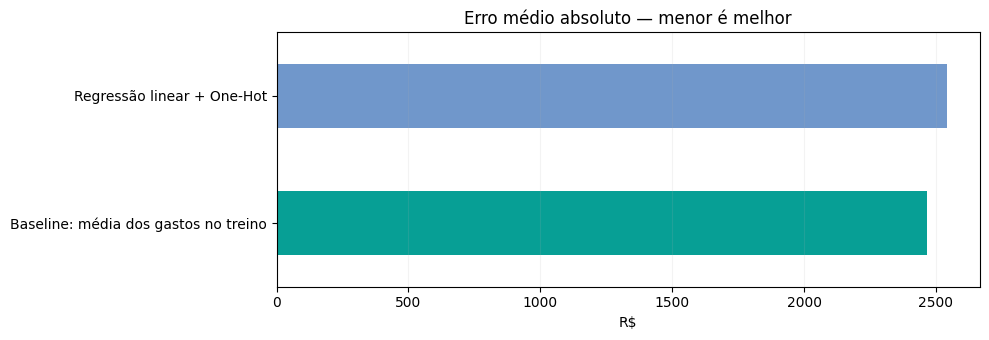

In [5]:
import matplotlib.pyplot as plt
ax=comparacao.plot.barh(x='método',y='MAE (R$)',legend=False,figsize=(10,3.5),color=['#7097CB','#079F95'])
ax.invert_yaxis()
ax.set(title='Erro médio absoluto — menor é melhor',xlabel='R$',ylabel='')
ax.grid(axis='x',alpha=.15)
plt.tight_layout();plt.show()


## Exportação do pipeline `.joblib`

Depois da avaliação, reajusto uma nova versão do pipeline com os sete registros apenas para demonstração no Streamlit. Salvo uma cópia do modelo **na pasta principal**, como solicitado, e outra junto ao `app.py` da Semana 10. O aplicativo carrega a cópia da Semana 10.

Se o banco for atualizado futuramente, é necessário treinar novamente; o modelo **não aprende** com lançamentos novos automaticamente.


In [6]:
import shutil
import json
import hashlib
from pathlib import Path
pasta_app=RAIZ/'semana_10_app_streamlit'
modelo_app=pasta_app/'modelo_despesas.joblib'
meta_app=pasta_app/'metadata_modelo.json'
meta=exportar(despesas,modelo_app,meta_app)
meta['sha256_banco_original']=hashlib.sha256(BANCO.read_bytes()).hexdigest()
meta_app.write_text(json.dumps(meta,indent=2,ensure_ascii=False),encoding='utf-8')
modelo_principal=RAIZ/'modelo_despesas.joblib'
shutil.copy2(modelo_app,modelo_principal)
assert modelo_app.is_file() and modelo_principal.is_file()
print('Modelo salvo em:')
print('-',modelo_app.relative_to(RAIZ))
print('-',modelo_principal.relative_to(RAIZ))
print('Hash de origem:',meta['sha256_banco_original'])
conexao.close()


Modelo salvo em:
- semana_10_app_streamlit/modelo_despesas.joblib
- modelo_despesas.joblib
Hash de origem: cc21e3e842b6371f7a98f92c8bafbcd44682ce4b27dc67197ff5da4e29da132a


## Conclusão

Com esta base, a regressão linear apresenta erro maior que a previsão pela média do treino. O teste tem apenas duas observações, uma delas com R$ 5.000,00; não há suporte estatístico para afirmar que o modelo prevê bem os próximos gastos. O `.joblib` serve para demonstrar o fluxo completo entre análise, treinamento e interface.
